# Synthetic biomarker benchmark

The generated pages hold the facts: [how it is run](../../docs/benchmarks/biomarker-synthetic-docs.md)
and [what came out](../../docs/benchmarks/biomarker-synthetic-results.md). The shapes themselves, and
the values their geometry requires, are in [the shapes
notebook](biomarker-synthetic-shapes.ipynb). This notebook is where the judgement goes.

**Everything here is measured over synthetically generated segmentations** — arteries, veins and an
optic disc *drawn* from equations, at a stated scale, on a blank field. No eye was photographed and
no annotator was consulted. That is the whole point: when the shape is drawn rather than traced,
what it ought to measure is not a matter of opinion.

## Two kinds of benchmarking, and they are different questions

1. **Sensitivity to rotation.** Every shape is drawn again at several angles, in continuous
   coordinates, rather than by turning a picture. The geometry is *identical* at each angle, so
   anything that moves is the implementation or the pixel grid beneath it. This needs no ground
   truth at all — it is a self-consistency check, and a program can fail it badly while still
   landing on the right answer on average.
2. **Agreement with ground truth.** The ground truth here is a **theoretical value stored alongside
   the images**, derived from the geometry before a single pixel was drawn. It is not an
   annotation and it is not another program's output. An implementation that disagrees with it is
   *wrong*, not merely different. Each value says how it is known — `exact`, `numerical`,
   `asymptotic` or resting on a `convention` — and where the geometry offers **no value** at all,
   the right answer is nothing, and a number is a fault (section 4.4).

The two can disagree about a program, and when they do that is itself the finding: a steady wrong
number and a jittery right one are different diseases with different cures.

## How to read the tables

Unless a section says otherwise, every table has **one row per canonical biomarker name** and **one
column per implementation** — the opposite way round from every other benchmark here, where the
model leads. It is that way because the question is *do these programs compute the same quantity*,
and a reader answering it reads **across a row**. Where a quantity was measured on several shapes
or at several angles, the cell holds the **worst** of them: a mean would hide exactly the case
worth knowing about.

**The columns stand in lineage order, not alphabetically**, and the order carries information:

| Columns | Why they stand together |
| --- | --- |
| `pvbm`, `ocular` | OCULAR imports PVBM's tortuosity, perimeter and branching-angle helpers at runtime and measures with a modified copy of its `CREVBMs` |
| `automorph`, `automorphalyzer`, `automorphclass` | both descendants are rewrites of AutoMorph's measuring stage |
| `vascx` | shares no code with any of the above; it reimplements every biomarker from the definitions |

So a difference **between neighbours** is a change somebody made on purpose, and a difference
**across a boundary** is two programs that never shared a line of code arriving at different
numbers for the same definition.

## Where the rest of the analysis is

The three groups above each have **a notebook of their own**, which goes further into that lineage
than this one can: its own columns held to what their authors say they compute, the cup-to-disc
ratios, and the best and worst biomarkers of each member.

| Group | Notebook |
| --- | --- |
| AutoMorph, AutoMorphalyzer, AutoMorphClass | [biomarker-synthetic-automorph.ipynb](biomarker-synthetic-automorph.ipynb) |
| PVBM, OCULAR | [biomarker-synthetic-pvbm.ipynb](biomarker-synthetic-pvbm.ipynb) |
| VascX | [biomarker-synthetic-vascx.ipynb](biomarker-synthetic-vascx.ipynb) |

This notebook keeps the comparison **across** them, by canonical name, which is the one thing no
group notebook can show: §1 to §5 per implementation, and §6 per group.

**The shapes now carry an optic cup** (0.40 × 0.55 of the disc's diameter),
and every adapter is handed it. The vertical and horizontal cup-to-disc ratios are read along the
image's axes, so turning the photograph is *meant* to move them; they are left out of every rotation
check below, and their agreement with the geometry is in §4 like any other biomarker's.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_synthetic as benchmark  # noqa: E402
from benchmarks import synthetic_evidence as se  # noqa: E402
from benchmarks.shapes import store  # noqa: E402
from biomarkers import canonical  # noqa: E402
from biomarkers.utils import catalogue  # noqa: E402

#: The two thresholds this notebook reports against. **Neither is a standard anybody agreed**: they
#: are reporting conveniences, chosen so that a table shows the handful of quantities worth looking
#: at rather than two hundred rows of nothing. Nothing passes or fails a benchmark here.
ROTATION_TOLERANCE = 0.10
GROUND_TRUTH_TOLERANCE = 0.25

#: The noise floor, as a fraction of a biomarker's **own size**, and it does two jobs: a difference
#: smaller than this is treated as agreement, and no percentage is ever taken against a denominator
#: smaller than this.
#:
#: **It is relative because the catalogue is no longer in one unit.** Every canonical length is now
#: in microns, so this benchmark's quantities run from an area of about 250,000 µm² to a squared
#: curvature of about 10⁻⁸ /µm². One absolute floor cannot serve both: the same constant that
#: ignores rasterisation noise on an area would forgive every answer τ7 can give. So the floor is
#: taken against each biomarker's own size — the largest value the shapes require of it anywhere in
#: the store, `SIZE` below — and is the same 1% for all of them.
#:
#: **Why 1%, which is unusually high.** These shapes are drawn onto a pixel lattice and
#: skeletonised, and that quantisation puts a floor under how exactly *any* program can answer.
#: Section 4 of the shapes notebook measures it: the drawn area of a straight vessel differs from
#: the area its geometry requires by about a tenth of a per cent at 2048 px, and by more on
#: anything thinner. Below that floor a percentage is a ratio of two noises and says nothing about
#: the software.
#:
#: **What it costs, which is worth knowing before reading any table below.** A biomarker whose
#: interesting values are small *relative to its own largest* is forgiven more than one whose are
#: not: total curvature is 0 on a straight vessel and 1.57 on a right-angled arc, so an
#: implementation answering 0.015 on the straight vessel is inside the floor. That is the intended
#: behaviour — it is the rasteriser, not the formula — but the honest reading of a small error is
#: "under the noise floor", not "correct".
NOISE = 0.01

#: Lineage order, from the benchmark's own groups, so the columns of every table below stand the way
#: the intro describes. Never re-sort this.
IMPLEMENTATIONS = [slug for members in benchmark.GROUPS.values() for slug in members]

#: The ratios read along the image's axes, which turning the photograph is meant to move.
from benchmarks.shapes.truth import TURN_WITH_THE_IMAGE  # noqa: E402
from benchmarks.shapes import claims  # noqa: E402

#: The unnamed columns whose own claimed value moves with the angle — a cup's height in the image,
#: where its centre lands — and so are left out of every rotation check, like the ratios above.
TURNING_OWN = claims.turning(ROOT / store.STORE)
EVIDENCE = ROOT / "results" / benchmark.NAME
STORE = ROOT / store.STORE
pd.set_option("display.width", 200, "display.max_rows", 300, "display.max_columns", 40)

In [2]:
def measured(slug: str) -> pd.DataFrame:
    """Everything one implementation returned, over every shape and every angle."""
    frames = [pd.read_csv(path) for path in sorted((EVIDENCE / slug).glob("*.csv"))]
    frame = pd.concat(frames, ignore_index=True)
    frame.insert(0, "implementation", slug)
    return frame


#: What each program said, under **its own** column names, exactly as the run wrote it.
MEASURED = {slug: measured(slug) for slug in IMPLEMENTATIONS}

#: Which catalogued biomarker each of those columns is believed to answer to, or `None` where the
#: catalogue has no name for that quantity. This is the adapter's claim, not the run's: a run
#: records no mapping at all, which is what lets the same evidence be re-read against a corrected
#: mapping without measuring anything again.
NAMES = {slug: catalogue.load(slug).declare()["names"] for slug in IMPLEMENTATIONS}


#: How many microns a pixel is worth, per rendering, read from the store's manifest. Every shape
#: here is drawn at one scale, but it is read rather than assumed: a conversion driven by a
#: constant somebody typed is the kind of thing this benchmark exists to catch.
SCALES = pd.DataFrame(store.read(STORE)).set_index("key")["um_per_px"].astype(float)


def answers(slug: str) -> pd.DataFrame:
    """One row per (implementation, rendering, column), as the run wrote it."""
    frame = MEASURED[slug]
    columns = [column for column in frame.columns if column.startswith("said_")]
    long = frame.melt(
        id_vars=["implementation", "key", "shape", "rotation", "outcome", "seconds"],
        value_vars=columns,
        var_name="said",
        value_name="returned",
    )
    long["own"] = long["said"].str[len("said_") :]
    return long


def worded(long: pd.DataFrame) -> pd.Series:
    """Which answers are a category rather than a number — AutoMorphalyzer's laterality says
    `Right` or `Left`. A word has no size, so it is kept apart from every numeric comparison below."""
    return long["returned"].notna() & pd.to_numeric(long["returned"], errors="coerce").isna()


def tidy(slug: str) -> pd.DataFrame:
    """One row per (implementation, rendering, quantity), with the canonical name beside it.

    **This is where pixels become microns.** Every adapter reports what its implementation
    returned, on the pixel grid, because that is what the implementation's own documentation
    describes. A canonical name is never in pixels, so a value claiming one is converted here —
    by `canonical.from_pixels`, the single rule the ground truth was built with — and the column
    that carries the implementation's own number is kept beside it, unconverted, so a reader
    checking against somebody's paper still finds the figure they published.
    """
    long = answers(slug)
    long = long[~worded(long)].astype({"returned": float})
    long["canonical"] = long["own"].map(NAMES[slug])
    long["um_per_px"] = long["key"].map(SCALES)
    long["value"] = [
        canonical.from_pixels(name, number, scale)
        if isinstance(name, str) and pd.notna(number)
        else number
        for name, number, scale in zip(
            long["canonical"], long["returned"], long["um_per_px"], strict=True
        )
    ]
    return long.drop(columns=["said"])


SAID = pd.concat([tidy(slug) for slug in IMPLEMENTATIONS], ignore_index=True)

#: The answers that are categories, under each implementation's own column name.
CATEGORIES = pd.concat(
    [long[worded(long)] for long in map(answers, IMPLEMENTATIONS)], ignore_index=True
).drop(columns=["said"])

#: How each value the geometry settles is known — `exact`, `numerical`, `asymptotic` or
#: `convention` — keyed the way the store keys a rendering, which is also the way the evidence keys a
#: row, so the joins below need no translation. A biomarker with a kind and no value is one the
#: geometry settles as having **none**.
KIND = pd.DataFrame(
    [
        {"key": key, "canonical": name, "kind": kind}
        for key, known in store.kinds(STORE).items()
        for name, kind in known.items()
    ]
)
_VALUES = pd.DataFrame(
    [
        {"key": key, "canonical": name, "truth": value}
        for key, values in store.truth(STORE).items()
        for name, value in values.items()
    ]
)
#: What the geometry requires, where it is a number.
TRUTH = (
    _VALUES[_VALUES["truth"].map(lambda value: not isinstance(value, str))]
    .astype({"truth": float})
    .merge(KIND, on=["key", "canonical"], how="left")
)
#: What it requires where the answer is a word — the photograph's centring, `disc` or `macula`.
WORDS = _VALUES[_VALUES["truth"].map(lambda value: isinstance(value, str))]
#: What it settles as having no value at all: no junction to take an angle at, no vessel in zone C,
#: no whole vessel where nothing reaches the disc. An implementation should decline these.
NONE = pd.DataFrame(
    [
        {"key": key, "canonical": name}
        for key, names in store.undefined(STORE).items()
        for name in names
    ]
)

#: Each catalogued biomarker's **own size**: the largest value the shapes require of it anywhere in
#: the store. It is what the noise floor is taken against, so that one constant serves an area in
#: µm² and a squared curvature in 1/µm² alike.
SIZE = TRUTH.assign(size=TRUTH["truth"].abs()).groupby("canonical")["size"].max()

#: The same for a quantity the catalogue cannot name: there is no ground truth to take a size from,
#: so it is taken from what the implementations themselves returned. A self-consistency check does
#: not need a correct answer, only a scale to judge movement against.
_OWN_SIZE = SAID.assign(size=SAID["value"].abs()).groupby(["implementation", "own"])["size"].max()
SAID["size"] = SAID["canonical"].map(SIZE)
SAID["size"] = SAID["size"].fillna(
    pd.Series(
        pd.MultiIndex.from_arrays([SAID["implementation"], SAID["own"]]).map(_OWN_SIZE),
        index=SAID.index,
    )
)

#: Whether turning the photograph is *meant* to move a quantity: the cup-to-disc ratios read along
#: the image's axes, and the unnamed columns whose own claimed value changes with the angle.
SAID["turns"] = SAID["canonical"].isin(TURN_WITH_THE_IMAGE) | pd.Series(
    [(slug, own) in TURNING_OWN for slug, own in zip(SAID["implementation"], SAID["own"], strict=True)],
    index=SAID.index,
)

SHAPES = sorted(SAID["shape"].unique())
print(
    f"{len(SAID):,} measurements — {len(IMPLEMENTATIONS)} implementations "
    f"× {len(SHAPES)} shapes × {SAID['rotation'].nunique()} angles; "
    f"{len(TRUTH) + len(WORDS):,} theoretical values to compare against, and {len(NONE):,} the "
    f"geometry says do not exist"
)

15,743 measurements — 6 implementations × 13 shapes × 7 angles; 72,009 theoretical values to compare against, and 5,999 the geometry says do not exist


In [3]:
def floor(size: float) -> float:
    """The smallest difference worth reporting for a biomarker of this size."""
    return NOISE * size if size and np.isfinite(size) else NOISE


def spread(values: pd.Series, size: float) -> float:
    """How far a quantity moved when the same shape was turned, relative to its own size.

    The floor twice over: a movement under it is agreement, and the denominator never falls below
    it either — so a quantity hovering around nought cannot report a large percentage for having
    moved an amount nobody could measure.
    """
    values = values.dropna()
    if len(values) < 2:
        return np.nan
    width = values.max() - values.min()
    smallest = floor(size)
    if width < smallest:
        return 0.0
    return width / max(abs(values.mean()), smallest)


def error(value: float, truth: float, size: float) -> float:
    """How far one measurement is from what the geometry requires, as a fraction of the truth.

    The same two uses of the floor. A disagreement smaller than it is not a disagreement, and a
    percentage is never taken against a truth smaller than it — which is what used to produce an
    infinity wherever the geometry required exactly nought.
    """
    gap = abs(value - truth)
    smallest = floor(size)
    if gap < smallest:
        return 0.0
    return gap / max(abs(truth), smallest)


def as_percent(table: pd.DataFrame) -> pd.DataFrame:
    """A table of fractions, shown as percentages a reader can scan."""
    return (table * 100).round(1)


def over(table: pd.DataFrame, tolerance: float) -> pd.DataFrame:
    """Only the rows where at least one implementation is outside the tolerance.

    Filtering is deliberate: a table of two hundred rows that are all zero hides the five that
    are not.
    """
    return table[(table > tolerance).any(axis=1)]


def columns_in_order(table: pd.DataFrame) -> pd.DataFrame:
    return table.reindex(columns=[c for c in IMPLEMENTATIONS if c in table.columns])


def heading(text: str) -> None:
    display(Markdown(text))

## 1. General statistics — how much there is, and how much of it can be compared

Three different things stand between a quantity a program computes and a number this benchmark can
judge, and keeping them apart is the first thing an analysis owes a reader:

- **The catalogue may have no name for it.** A perimeter, a singularity length, the standard
  deviation of a branching angle — these are measured and stored under the implementation's own
  name, because a canonical name exists to make two numbers comparable and there is no second
  number to compare against yet.
- **No shape may settle it.** A quantity can have a catalogued name and still have no theoretical
  value here, if no drawn shape pins one down. It is reported and left unchecked.
- **The program may simply not have answered**, on any shape.

An implementation returning forty columns of which eight can be compared is in a very different
position from one returning eight that all can, and a single count of "columns" hides it.

In [4]:
def statistics(slug: str) -> dict[str, object]:
    frame = MEASURED[slug]
    said = SAID[SAID["implementation"] == slug]
    with_value = set(said.loc[said["value"].notna(), "own"])
    with_value |= set(CATEGORIES.loc[CATEGORIES["implementation"] == slug, "own"])
    canonical = {own for own, name in NAMES[slug].items() if name}
    return {
        "biomarkers produced": len(NAMES[slug]),
        "…that returned a value": len(with_value),
        "matching a canonical name": len(canonical),
        "…of those, returning a value": len(with_value & canonical),
        "unnamed, but returning a value": len(with_value - canonical),
        "seconds per image": round(frame["seconds"].astype(float).mean(), 1),
    }


pd.DataFrame({slug: statistics(slug) for slug in IMPLEMENTATIONS})

,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
biomarkers produced,18.0,64.0,24.0,30.0,18.0,20.0
…that returned a value,18.0,50.0,24.0,30.0,18.0,20.0
matching a canonical name,15.0,33.0,17.0,20.0,10.0,6.0
"…of those, returning a value",15.0,33.0,17.0,20.0,10.0,6.0
"unnamed, but returning a value",3.0,17.0,7.0,10.0,8.0,14.0
seconds per image,1.7,7.0,1.5,64.9,4.8,5.2


### 1.1 What each implementation computes that the catalogue cannot name

Naming these is the point. Each one is either a gap in the catalogue or a mapping nobody has made
yet, and the list below is what turns "eleven unnamed columns" into work somebody can actually do.
A quantity in this list is measured and stored; it is simply absent from every comparison after
this section, because there is nothing to compare it with.

In [5]:
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    said = SAID[SAID["implementation"] == slug]
    with_value = set(said.loc[said["value"].notna(), "own"])
    unnamed = sorted(own for own in with_value if not NAMES[slug].get(own))
    heading(f"#### 1.1.{number} {slug} — {len(unnamed)} unnamed")
    if unnamed:
        display(pd.DataFrame({"its own name for it": unnamed}))
    else:
        print("every quantity it returns has a canonical name")

#### 1.1.1 automorph — 3 unnamed

,its own name for it
0,squared_curvature_tortuosity_artery
1,squared_curvature_tortuosity_binary
2,squared_curvature_tortuosity_vein


#### 1.1.2 automorphalyzer — 16 unnamed

,its own name for it
0,average_local_calibre@B_artery
1,average_local_calibre@B_binary
2,average_local_calibre@B_vein
3,average_local_calibre@C_artery
4,average_local_calibre@C_binary
5,average_local_calibre@C_vein
6,average_local_calibre@whole_artery
7,average_local_calibre@whole_binary
8,average_local_calibre@whole_vein
9,cup_centre_x


#### 1.1.3 automorphclass — 7 unnamed

,its own name for it
0,cup_height
1,cup_width
2,disc_height
3,disc_width
4,squared_curvature_tortuosity_artery
5,squared_curvature_tortuosity_vein
6,squared_curvature_tortuosity_vessels


... (2 outputs left out)

#### 1.1.5 ocular — 8 unnamed

,its own name for it
0,endpoints_artery
1,endpoints_vein
2,median_branching_angle_artery
3,median_branching_angle_vein
4,pooled_tortuosity_artery
5,pooled_tortuosity_vein
6,start_points_artery
7,start_points_vein


#### 1.1.6 vascx — 14 unnamed

,its own name for it
0,disc_fovea_distance_center_retina
1,disc_fovea_distance_retina
2,lw_tort_curv_crcl_multiplier_1p16666666667_ful...
3,lw_tort_curv_crcl_multiplier_1p16666666667_ful...
4,lw_tort_dist_max_segment_len_0p15_crcl_multipl...
5,lw_tort_dist_max_segment_len_0p15_crcl_multipl...
6,lw_tort_dist_max_segment_len_0p25_crcl_multipl...
7,lw_tort_dist_max_segment_len_0p25_crcl_multipl...
8,mean_sparsity_crcl_multiplier_1p16666666667_fu...
9,mean_sparsity_vessels


## 2. Hard failures — what raised, and on what

A failure is **not** a bad measurement, and the two are never merged. An implementation that raises
has told you it could not answer; one that returns a confident wrong number has not. This section
is the first kind only.

The table is complete rather than summarised, because it exists to be debugged from later: a reader
must be able to reproduce one row of it from the row alone.

In [6]:
troubles = []
for slug in IMPLEMENTATIONS:
    frame = MEASURED[slug]
    noted = frame[frame["note"].notna() & (frame["note"].astype(str).str.strip() != "")]
    for _, row in noted.iterrows():
        for complaint in str(row["note"]).split("; "):
            what, _, why = complaint.partition(": ")
            troubles.append(
                {
                    "implementation": slug,
                    "shape": row["shape"],
                    "rotation": row["rotation"],
                    "what it could not answer": what,
                    "what it raised": why,
                }
            )
    for _, row in frame[frame["outcome"] == "failed"].iterrows():
        troubles.append(
            {
                "implementation": slug,
                "shape": row["shape"],
                "rotation": row["rotation"],
                "what it could not answer": "everything",
                "what it raised": str(row["note"]) or "nothing came back",
            }
        )

TROUBLES = pd.DataFrame(troubles)
print(f"{len(TROUBLES)} exceptions, over {len(SAID['key'].unique())} renderings")
TROUBLES

21 exceptions, over 91 renderings


,implementation,shape,rotation,what it could not answer,what it raised
0,automorphalyzer,disjoint,0.0,measure_artery,ZeroDivisionError('division by zero')
1,automorphalyzer,disjoint,0.0,measure_vein,ZeroDivisionError('division by zero')
2,automorphalyzer,disjoint,0.0,measure_binary,ZeroDivisionError('division by zero')
3,automorphalyzer,disjoint,15.0,measure_artery,ZeroDivisionError('division by zero')
4,automorphalyzer,disjoint,15.0,measure_vein,ZeroDivisionError('division by zero')
5,automorphalyzer,disjoint,15.0,measure_binary,ZeroDivisionError('division by zero')
6,automorphalyzer,disjoint,30.0,measure_artery,ZeroDivisionError('division by zero')
7,automorphalyzer,disjoint,30.0,measure_vein,ZeroDivisionError('division by zero')
8,automorphalyzer,disjoint,30.0,measure_binary,ZeroDivisionError('division by zero')
9,automorphalyzer,disjoint,45.0,measure_artery,ZeroDivisionError('division by zero')


## 3. Section 3 — sensitivity to rotation

The geometry is identical at every angle, so **any spread at all is the implementation or the pixel
grid beneath it**. Nothing in this section touches the ground truth: it is a check a program can be
put through without anybody knowing the right answer, which is what makes it worth doing on the
quantities no shape settles.

Each cell is the **worst spread that quantity showed on any shape** — the width across the seven
angles, as a percentage of its mean on that shape, pooled over every shape by taking the largest.
Pooling this way is deliberate: a quantity that turns with the image on one shape turns with the
image, and averaging that away across eight well-behaved shapes would be a way of not noticing.

Rows are filtered to those where at least one implementation exceeds **10%**
(`ROTATION_TOLERANCE`).

In [7]:
named = SAID[SAID["canonical"].notna()]
turning = named["canonical"].isin(TURN_WITH_THE_IMAGE)
by_shape = named[~turning].groupby(["implementation", "canonical", "shape"], group_keys=True).apply(
    lambda group: spread(group["value"], group["size"].iloc[0]), include_groups=False
)
ROTATION = columns_in_order(
    by_shape.groupby(["implementation", "canonical"]).max().unstack("implementation")
)
unsteady = over(ROTATION, ROTATION_TOLERANCE)
print(
    f"{len(unsteady)} of {len(ROTATION)} canonical biomarkers move by more than "
    f"{ROTATION_TOLERANCE:.0%} on at least one implementation, worst shape shown:"
)
se.legible(unsteady)

42 of 55 canonical biomarkers move by more than 10% on at least one implementation, worst shape shown:


implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
canonical,,,,,,
calibre/AVR-hubbard/both/B,—,—,—,26.3%,—,—
calibre/AVR-knudtson/both/B,—,—,—,26.3%,—,—
calibre/CRE-hubbard/artery/B,—,—,—,27.0%,—,—
calibre/CRE-hubbard/vein/B,—,—,—,10.2%,—,—
calibre/CRE-knudtson/artery/B,—,4.3%,—,27.0%,—,4.1%
calibre/CRE-knudtson/vein/B,—,4.4%,—,11.9%,—,1.9%
calibre/CRE-knudtson/vein/C,—,19.5%,—,—,—,—
calibre/width/artery/length-weighted,99.2%,63.6%,65.7%,—,—,4.0%
calibre/width/vein/length-weighted,48.8%,33.4%,37.5%,—,—,1.9%


### 3.1 The same question for the quantities nothing can compare

A quantity the catalogue cannot name is as capable of turning with the image as one it can, and
nothing else in this notebook would notice. This is the only check those columns get.

In [8]:
unnamed_rows = SAID[SAID["canonical"].isna() & SAID["value"].notna() & ~SAID["turns"]]
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    mine = unnamed_rows[unnamed_rows["implementation"] == slug]
    heading(f"#### 3.1.{number} {slug}")
    if mine.empty:
        print("nothing unnamed to check")
        continue
    table = (
        mine.groupby(["own", "shape"], group_keys=True)
        .apply(lambda group: spread(group["value"], group["size"].iloc[0]), include_groups=False)
        .groupby("own")
        .max()
    )
    table = table[table > ROTATION_TOLERANCE].sort_values(ascending=False)
    if table.empty:
        print(f"every unnamed quantity holds steady to within {ROTATION_TOLERANCE:.0%}")
    else:
        display((table * 100).round(1).to_frame("worst spread across angles, %"))

#### 3.1.1 automorph

,"worst spread across angles, %"
own,
squared_curvature_tortuosity_artery,697.2
squared_curvature_tortuosity_binary,694.5
squared_curvature_tortuosity_vein,684.7


#### 3.1.2 automorphalyzer

,"worst spread across angles, %"
own,
average_local_calibre@whole_vein,27.3
average_local_calibre@whole_binary,13.0
average_local_calibre@whole_artery,10.8
average_local_calibre@C_artery,10.7
average_local_calibre@B_binary,10.3
average_local_calibre@B_artery,10.1


#### 3.1.3 automorphclass

,"worst spread across angles, %"
own,
squared_curvature_tortuosity_artery,285.1
squared_curvature_tortuosity_vessels,282.3
squared_curvature_tortuosity_vein,279.9


... (2 outputs left out)

#### 3.1.5 ocular

,"worst spread across angles, %"
own,
median_branching_angle_vein,67.1
median_branching_angle_artery,47.8
endpoints_artery,35.9
start_points_artery,35.9
endpoints_vein,25.2
pooled_tortuosity_artery,14.5
pooled_tortuosity_vein,13.9


#### 3.1.6 vascx

,"worst spread across angles, %"
own,
lw_tort_curv_crcl_multiplier_1p16666666667_full_arteries,493.6
lw_tort_curv_crcl_multiplier_1p16666666667_full_veins,232.9
median_temporal_angle_arteries,46.5
median_temporal_angle_veins,37.0
lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_veins,15.6
lw_tort_dist_max_segment_len_0p25_crcl_multiplier_1p16666666667_full_arteries,13.0


### 3.2 The single worst case each implementation produced

The tables above give a spread as a percentage, which says *how much* a quantity moved and nothing
about what it moved **between**. A spread of 240% could be 1 against 3.4, or 0.001 against 0.0034,
and those are not the same finding: the first is a count that cannot make up its mind and the
second is noise in a number nobody would quote to three figures.

So this is the worst case each implementation produced anywhere — the quantity, the shape, and the
two angles that bracket it, **with the values themselves**. Every quantity is eligible, canonical
or not, because a program's worst behaviour does not check whether the catalogue has a name for it.

Read it as a place to start debugging rather than as a score. One bad shape is one bad shape.

In [9]:
def worst_rotation_case(slug: str) -> dict[str, object] | None:
    """The (quantity, shape) whose value moved most across the angles."""
    mine = SAID[
        (SAID["implementation"] == slug)
        & SAID["value"].notna()
        & ~SAID["turns"]
    ]
    best = None
    for (own, shape), group in mine.groupby(["own", "shape"]):
        values = group.dropna(subset=["value"])
        if len(values) < 2:
            continue
        moved = spread(values["value"], values["size"].iloc[0])
        if not moved:
            continue          # under the noise floor: not a disagreement worth ranking
        if best is None or moved > best["spread"]:
            low = values.loc[values["value"].idxmin()]
            high = values.loc[values["value"].idxmax()]
            best = {
                "quantity": own,
                "canonical": group["canonical"].iloc[0] or "—",
                "shape": shape,
                "spread": moved,
                "at min": f"{low['rotation']:.0f}°",
                "min": low["value"],
                "at max": f"{high['rotation']:.0f}°",
                "max": high["value"],
            }
    return best


rows = []
for slug in IMPLEMENTATIONS:
    found = worst_rotation_case(slug)
    if found is None:
        continue
    rows.append({"implementation": slug, **found})

WORST = pd.DataFrame(rows).set_index("implementation")
WORST["spread"] = (100 * WORST["spread"]).round(0).astype(int).astype(str) + "%"
WORST[["quantity", "shape", "spread", "at min", "min", "at max", "max", "canonical"]]

,quantity,shape,spread,at min,min,at max,max,canonical
implementation,,,,,,,,
automorph,tortuosity_density_artery,crossing,700%,15°,0.000000,0°,0.079012,tortuosity/grisan-density/artery/mean
automorphalyzer,tortuosity_density@B_vein,bifurcation,700%,0°,0.000000,90°,0.153510,tortuosity/grisan-density/vein/B/mean
automorphclass,squared_curvature_tortuosity_artery,straight,285%,45°,0.000000,15°,25.369500,—
pvbm,intersections_artery,koch,210%,30°,0.000000,15°,3.000000,topology/junctions/artery
ocular,intersections_artery,koch,210%,30°,0.000000,15°,3.000000,topology/junctions/artery
vascx,lw_tort_curv_crcl_multiplier_1p16666666667_ful...,spokes-macula-centred,494%,45°,0.000897,60°,0.254731,—


## 4. Section 4 — agreement with ground truth

Here the number on the other side of the comparison is not another program's: it is what the
geometry **requires**, worked out from the equations the shape was drawn from. A disagreement is
therefore a fault rather than a difference of opinion.

**The main table holds the worst disagreement over every shape and every angle** — one number per
implementation per biomarker, the worst case it produced anywhere, as a percentage of the truth.
Rows are filtered to those with at least one fault, where a fault is more than **25%**
(`GROUND_TRUTH_TOLERANCE`).

Only canonical names appear, because only they have a ground truth to disagree with. A quantity
computed under a name the catalogue does not know is measured, stored, and absent from here — which
is a gap rather than a pass, and section 1's subsections say which quantities those are.

**Both sides of the comparison are in the biomarker's own unit** — microns, µm², 1/µm — never in
pixels. Each implementation reports what it measured on the pixel grid and that number is
converted once, by the same rule the ground truth was built with, so the comparison is between two
physical quantities rather than between a physical one and a count of pixels. Section 4.2 shows
both figures side by side.

Where the geometry requires exactly nought — a straight vessel has no inflections — there is no
percentage of nought to take, so the denominator falls back to the noise floor, which is 1% of
that biomarker's own largest value across the store. A program that finds structure in a shape
that has none therefore reports a large but finite error rather than an infinity, and how large
depends on the floor rather than on the truth. Section 4.2 shows the values themselves, which is
the only way to read those rows.

In [10]:
AGAINST = named.merge(TRUTH, on=["key", "canonical"], how="inner").dropna(subset=["value"])
AGAINST["error"] = [
    error(value, truth, size)
    for value, truth, size in zip(
        AGAINST["value"], AGAINST["truth"], AGAINST["size"], strict=True
    )
]


def worst_over(frame: pd.DataFrame) -> pd.DataFrame:
    """The worst disagreement each implementation produced, per canonical name."""
    return columns_in_order(
        frame.groupby(["canonical", "implementation"])["error"].max().unstack("implementation")
    )


EVERYWHERE = worst_over(AGAINST)
faults = over(EVERYWHERE, GROUND_TRUTH_TOLERANCE)
print(
    f"{len(AGAINST):,} measurements have a theoretical value to be judged against, over "
    f"{AGAINST['canonical'].nunique()} canonical biomarkers; {len(faults)} of them are out by more "
    f"than {GROUND_TRUTH_TOLERANCE:.0%} somewhere. Worst over all shapes × angles:"
)
se.legible(faults)

8,136 measurements have a theoretical value to be judged against, over 57 canonical biomarkers; 39 of them are out by more than 25% somewhere. Worst over all shapes × angles:


implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
canonical,,,,,,
calibre/AVR-hubbard/both/B,—,—,—,47.0%,—,—
calibre/CRE-hubbard/artery/B,—,—,—,30.9%,—,—
calibre/CRE-hubbard/vein/B,—,—,—,55.8%,—,—
calibre/CRE-knudtson/artery/B,—,52.3%,—,28.5%,—,2.9%
calibre/CRE-knudtson/artery/C,—,106.6%,—,—,—,—
calibre/CRE-knudtson/vein/B,—,67.4%,—,30.4%,—,2.4%
calibre/CRE-knudtson/vein/C,—,179.2%,—,—,—,—
calibre/width/artery/length-weighted,71.3%,67.7%,71.2%,—,—,2.7%
calibre/width/vein/length-weighted,32.7%,40.3%,46.9%,—,—,2.2%


### 4.1 The same table, one shape at a time

The main table says **whether** a biomarker can be trusted. It cannot say **where** it stopped
being trustworthy, and that is the difference between a number and something somebody can go and
investigate: a biomarker wrong on one shape and right on eight is a different finding from one
wrong on all thirteen, and the worst-case column above cannot tell them apart.

Each table below is the worst disagreement over the seven angles of that shape alone.

In [11]:
for number, shape in enumerate(SHAPES, start=1):
    here = AGAINST[AGAINST["shape"] == shape]
    table = over(worst_over(here), GROUND_TRUTH_TOLERANCE)
    heading(f"#### 4.1.{number} {shape} — {len(table)} biomarkers out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    if table.empty:
        print("every comparable biomarker lands within tolerance on this shape")
    else:
        display(se.legible(table))

#### 4.1.1 arc — 14 biomarkers out by more than 25%

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular
canonical,,,,,
tortuosity/grisan-density/artery/B/mean,—,"334,440×",—,—,—
tortuosity/grisan-density/artery/C/mean,—,"202,705×",—,—,—
tortuosity/grisan-density/artery/length-weighted,—,—,"1,692×",—,—
tortuosity/grisan-density/artery/mean,"85,872×","170,997×",—,—,—
tortuosity/grisan-density/vein/B/mean,—,"322,563×",—,—,—
tortuosity/grisan-density/vein/C/mean,—,"202,514×",—,—,—
tortuosity/grisan-density/vein/length-weighted,—,—,"1,715×",—,—
tortuosity/grisan-density/vein/mean,"164,587×","170,452×",—,—,—
tortuosity/grisan-density/vessels/B/mean,—,"328,501×",—,—,—


#### 4.1.2 bifurcation — 15 biomarkers out by more than 25%

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular
canonical,,,,,
tortuosity/grisan-density/artery/B/mean,—,"335,084×",—,—,—
tortuosity/grisan-density/artery/C/mean,—,"201,184×",—,—,—
tortuosity/grisan-density/artery/length-weighted,—,—,"2,205×",—,—
tortuosity/grisan-density/artery/mean,"143,119×","170,167×",—,—,—
tortuosity/grisan-density/vein/B/mean,—,"328,268×",—,—,—
tortuosity/grisan-density/vein/C/mean,—,"133,569×",—,—,—
tortuosity/grisan-density/vein/length-weighted,—,—,"2,158×",—,—
tortuosity/grisan-density/vein/mean,"146,923×","113,202×",—,—,—
tortuosity/grisan-density/vessels/B/mean,—,"331,336×",—,—,—


#### 4.1.3 clothoid — 15 biomarkers out by more than 25%

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular
canonical,,,,,
tortuosity/grisan-density/artery/B/mean,—,"334,823×",—,—,—
tortuosity/grisan-density/artery/C/mean,—,"202,477×",—,—,—
tortuosity/grisan-density/artery/length-weighted,—,—,"1,807×",—,—
tortuosity/grisan-density/artery/mean,"147,209×","171,008×",—,—,—
tortuosity/grisan-density/vein/B/mean,—,"334,735×",—,—,—
tortuosity/grisan-density/vein/C/mean,—,"202,105×",—,—,—
tortuosity/grisan-density/vein/length-weighted,—,—,"1,709×",—,—
tortuosity/grisan-density/vein/mean,"158,532×","169,769×",—,—,—
tortuosity/grisan-density/vessels/B/mean,—,"167,412×",—,—,—


... (16 outputs left out)

#### 4.1.12 straight — 19 biomarkers out by more than 25%

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular
canonical,,,,,
calibre/width/artery/length-weighted,33.2%,32.0%,36.3%,—,—
calibre/width/vein/length-weighted,32.7%,40.3%,45.3%,—,—
calibre/width/vessels/length-weighted,16.8%,36.9%,41.7%,—,—
density/over-image/artery,29.0%,0.0%,0.0%,—,—
tortuosity/grisan-density/artery/B/mean,—,"334,642×",—,—,—
tortuosity/grisan-density/artery/C/mean,—,"203,093×",—,—,—
tortuosity/grisan-density/artery/length-weighted,—,—,"3,268×",—,—
tortuosity/grisan-density/artery/mean,0.0%,"171,365×",—,—,—
tortuosity/grisan-density/vein/B/mean,—,"334,610×",—,—,—


#### 4.1.13 tree — 18 biomarkers out by more than 25%

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
canonical,,,,,,
calibre/CRE-knudtson/artery/C,—,42.5%,—,—,—,—
calibre/CRE-knudtson/vein/C,—,70.8%,—,—,—,—
density/multifractal-d0/vein,—,—,—,25.0%,—,—
tortuosity/grisan-density/artery/B/mean,—,"219,302×",—,—,—,—
tortuosity/grisan-density/artery/C/mean,—,"143,159×",—,—,—,—
tortuosity/grisan-density/artery/length-weighted,—,—,"2,267×",—,—,—
tortuosity/grisan-density/artery/mean,"137,261×","121,002×",—,—,—,—
tortuosity/grisan-density/vein/B/mean,—,"219,302×",—,—,—,—
tortuosity/grisan-density/vein/C/mean,—,"143,147×",—,—,—,—


### 4.2 The single worst disagreement each implementation produced

The same objection as section 3.2, and the same answer. A table of percentages says how far a
number is from the geometry and not what either number **was**, so a 100% error could be 2 against
4 or 0 against anything at all — and "it returned nothing where the geometry requires something" is
a different fault from "it returned twice too much".

So this is the worst single disagreement each implementation produced anywhere: the quantity under
**its own name**, the catalogued name it answers to, the shape and angle it happened on, and both
values side by side.

Only canonical names can appear, because only they have a ground truth to disagree with. Where the
geometry requires exactly nought, the percentage is taken against the noise floor rather than the
truth, which is why the two value columns matter more than the percentage. Errors above ten times
the truth are written as a multiple (`57×`) rather than as a percentage with eight digits.

In [12]:
def worst_truth_case(slug: str) -> dict[str, object] | None:
    """The single measurement furthest from what the geometry requires."""
    mine = AGAINST[AGAINST["implementation"] == slug]
    if mine.empty:
        return None
    row = mine.loc[mine["error"].idxmax()]
    return {
        "quantity": row["own"],
        "canonical": row["canonical"],
        "shape": row["shape"],
        "rotation": f"{row['rotation']:.0f}°",
        "ground truth": row["truth"],
        "in canonical units": row["value"],
        "it returned": row["returned"],
        "error": f"{100 * row['error']:.0f}%",
    }


rows = [
    {"implementation": slug, **found}
    for slug in IMPLEMENTATIONS
    if (found := worst_truth_case(slug)) is not None
]
WORST_TRUTH = pd.DataFrame(rows).set_index("implementation")
WORST_TRUTH[
    [
        "quantity",
        "canonical",
        "shape",
        "rotation",
        "ground truth",
        "in canonical units",
        "it returned",
        "error",
    ]
]

,quantity,canonical,shape,rotation,ground truth,in canonical units,it returned,error
implementation,,,,,,,,
automorph,tortuosity_density_vein,tortuosity/grisan-density/vein/mean,arc,60°,0.000000,0.151440,0.958333,16458731%
automorphalyzer,tortuosity_density@B_artery,tortuosity/grisan-density/artery/B/mean,bifurcation,45°,0.000000,0.156697,0.991597,33508373%
automorphclass,tortuosity_density_vein,tortuosity/grisan-density/vein/length-weighted,crossing,15°,0.000000,0.003060,0.019361,332512%
pvbm,intersections_vein,topology/junctions/vein,koch,90°,0.000000,4.000000,4.000000,5714%
ocular,intersections_vein,topology/junctions/vein,koch,90°,0.000000,4.000000,4.000000,5714%
vascx,lw_tort_dist_max_segment_len_0p2_crcl_multipli...,tortuosity/hart-tau1/artery/length-weighted,koch,45°,1.777778,1.005299,1.005299,43%


### 4.3 How the ground truth is known, and what disagrees with each kind

Not every value above is known the same way. Most are **exact** — a closed form, or integrated along
the centreline far below any measurement's error. Sparsity is **numerical**, averaged on a 20 µm
grid. A fractal dimension is **asymptotic**: the limit a box count tends to, which no finite raster
reaches, so an honest implementation is expected to land near it rather than on it. And a few rest on
a **convention** — a crossing read as two vessels rather than a junction, a lone vessel passed
through Knudtson's pairing, which two branches of a four-way junction are its daughters — where a
disagreement may be a different reading of the definition rather than an error.

So the disagreements are split by kind. A fault against an `exact` value is a fault; one against a
`convention` is a question about the definition.

In [13]:
by_kind = (
    AGAINST.assign(out=AGAINST["error"] > GROUND_TRUTH_TOLERANCE)
    .groupby(["kind", "implementation"])["out"]
    .agg(lambda out: f"{int(out.sum())} / {len(out)}")
    .unstack("implementation")
)
print(
    f"measurements out by more than {GROUND_TRUTH_TOLERANCE:.0%}, over all comparable "
    f"measurements, by how the value is known:"
)
columns_in_order(by_kind)

measurements out by more than 25%, over all comparable measurements, by how the value is known:


implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
kind,,,,,,
asymptotic,11 / 273,7 / 252,8 / 273,61 / 546,NaN,NaN
convention,NaN,28 / 28,NaN,7 / 394,7 / 28,NaN
exact,282 / 1071,560 / 2203,254 / 1253,59 / 808,19 / 854,14 / 153


### 4.4 Where the geometry gives no value

Some biomarkers have **no value** on some shapes, by definition: a straight vessel has no junction to
take a branching angle at, nothing of the parallel orphans reaches zone B, and a vessel that never
reaches the disc has no whole-vessel tortuosity. That is not zero. The right answer is *nothing*, and
an implementation that returns a number there has invented one — the failure the vocabulary's rule
against substituting a default exists to prevent.

Counted per canonical biomarker: how many renderings each implementation answered with a number where
the geometry offers none, out of how many it was asked about. Only biomarkers some implementation
answered are listed; the rest were declined everywhere, as they should be.

In [14]:
INVENTED = named.merge(NONE, on=["key", "canonical"], how="inner")
INVENTED = INVENTED.assign(invented=INVENTED["value"].notna())
asked = INVENTED.groupby(["canonical", "implementation"])["invented"]
invented = columns_in_order(
    (asked.sum().astype(int).astype(str) + " / " + asked.size().astype(str)).unstack(
        "implementation"
    )
)
answered_somewhere = INVENTED.groupby("canonical")["invented"].any()
print(
    f"{int(INVENTED['invented'].sum()):,} numbers returned where the geometry offers none, out of "
    f"{len(INVENTED):,} chances, over {INVENTED['canonical'].nunique()} canonical biomarkers; "
    f"{int(answered_somewhere.sum())} of them were answered by somebody:"
)
invented.loc[answered_somewhere[answered_somewhere].index]

0 numbers returned where the geometry offers none, out of 168 chances, over 20 canonical biomarkers; 0 of them were answered by somebody:


implementation,automorphalyzer,pvbm,vascx
canonical,,,


### 4.5 The one answer that is a word

The photograph's **centring** — `disc` where the disc sits near the frame centre, `macula`
otherwise — is the vocabulary's one categorical biomarker. Every shape but `spokes-disc-centred`
is macula-centred. Which implementations answer it, and whether they agree with the framing:

In [15]:
centring = CATEGORIES.assign(canonical=[
    NAMES[slug].get(own) for slug, own in zip(CATEGORIES["implementation"], CATEGORIES["own"])
]).merge(WORDS, on=["key", "canonical"], how="inner")
if centring.empty:
    print("no implementation answers a categorical biomarker the store settles")
else:
    centring["agrees"] = centring["returned"] == centring["truth"]
    display(
        centring.groupby(["implementation", "shape", "truth", "returned"])
        .size()
        .rename("renderings")
        .to_frame()
    )

no implementation answers a categorical biomarker the store settles


## 5. Summary

Two counts, each written as a fraction so that the denominator is visible. **The denominators are
different on purpose**: rotation can be checked on anything that returned a number at all, and
agreement only on what the catalogue can name *and* a shape can settle. Reporting both against one
denominator would make one of them a lie.

In [16]:
#: Rotation spread for **every** quantity, named or not — which is the denominator the summary
#: needs, because a self-consistency check does not require a canonical name.
returned = SAID[SAID["value"].notna() & ~SAID["turns"]]
EVERY_ROTATION = (
    returned.groupby(["implementation", "own", "shape"], group_keys=True)
    .apply(lambda group: spread(group["value"], group["size"].iloc[0]), include_groups=False)
    .groupby(["implementation", "own"])
    .max()
)

summary = []
for slug in IMPLEMENTATIONS:
    steady = EVERY_ROTATION.loc[slug].dropna()
    judged = EVERYWHERE[slug].dropna()
    mine = AGAINST[AGAINST["implementation"] == slug]
    summary.append(
        {
            "implementation": slug,
            "rotation problems": f"{int((steady > ROTATION_TOLERANCE).sum())} / {len(steady)}",
            "disagrees with geometry": f"{int((judged > GROUND_TRUTH_TOLERANCE).sum())} / {len(judged)}",
            "exceptions": int((TROUBLES["implementation"] == slug).sum()) if len(TROUBLES) else 0,
            # Not a score, and not comparable across columns without reading what each column
            # *contains*: an implementation measuring six quantities well is not better than one
            # measuring twenty-two adequately, it is answering a smaller question.
            "comparable measurements": int(mine.shape[0]),
            "median disagreement": f"{np.median(mine['error']) * 100:.1f}%",
            "within 25% of the geometry": f"{(mine['error'] <= GROUND_TRUTH_TOLERANCE).mean():.0%}",
            "seconds per image": round(MEASURED[slug]["seconds"].astype(float).mean(), 1),
        }
    )

pd.DataFrame(summary).set_index("implementation").T

implementation,automorph,automorphalyzer,automorphclass,pvbm,ocular,vascx
rotation problems,16 / 18,23 / 43,10 / 20,24 / 30,13 / 18,8 / 20
disagrees with geometry,11 / 15,17 / 33,7 / 17,15 / 20,4 / 10,2 / 6
exceptions,0,21,0,0,0,0
comparable measurements,1344,2483,1526,1748,882,153
median disagreement,8.6%,6.1%,5.6%,4.9%,0.0%,0.0%
within 25% of the geometry,78%,76%,83%,93%,97%,91%
seconds per image,1.7,7.0,1.5,64.9,4.8,5.2


### 5.1 What this does not say

- **It does not rank the implementations.** No column is scored and no order is published. What can
  legitimately be argued from this evidence is *which implementation to reach for at a named
  question* — calibre, or tortuosity, or surviving a rotation — with the caveats that would change
  the answer. That argument belongs on the results page, where a reader can disagree with it. A
  column sorted by score would not be an argument at all.
- **It does not say a quantity with no ground truth is wrong**, or right. It is unchecked, which is
  a third thing.
- **It does not treat agreement between two implementations as evidence that either is correct.**
  Two of these groups share a lineage: where siblings agree, that is evidence about their common
  ancestor and nothing more.
- **It does not say anything about photographs.** Every shape here is clean, complete and drawn to
  a known scale. A program that measures a drawn arc correctly has cleared the lowest bar there is,
  not the one that matters clinically.

## 6. The three groups compared, by canonical name

Sections 1 to 5 compare implementations. This one compares **lineages**, which is the comparison a
reader choosing software usually wants: *if I reach for this family of code, which numbers can I
take at face value?* Each group answers a canonical name with **its closest member** — the one whose
worst error on that name is smallest — so a cell says what the best of that lineage can do, not what
every member does. Where siblings differ, the group notebook says which and why.

The same evidence, the same noise floor and the same two tolerances as above, read through
`benchmarks.synthetic_evidence` so that this notebook and the three group notebooks cannot disagree
about what an error is.

In [17]:
GROUPS = dict(benchmark.GROUPS)
GROUP_OF = {slug: group for group, members in GROUPS.items() for slug in members}
EVIDENCE = se.read(IMPLEMENTATIONS, ROOT)
BY_NAME = se.agreement(EVIDENCE)
BY_NAME["group"] = BY_NAME["implementation"].map(GROUP_OF)
FAMILY = lambda name: name.split("/")[0]  # noqa: E731


def closest(frame: pd.DataFrame, measure: str) -> pd.DataFrame:
    """Per canonical name and group, the worst case of the member that came closest."""
    worst = frame.groupby(["canonical", "group", "implementation"])[measure].max()
    return worst.groupby(["canonical", "group"]).min().unstack("group").reindex(columns=list(GROUPS))


GROUP_TRUTH = closest(BY_NAME, "error")
answered = GROUP_TRUTH.notna().sum(axis=1)
print(
    f"{len(GROUP_TRUTH)} canonical names have a ground truth some group answers; "
    f"{int((answered == 3).sum())} are answered by all three groups, {int((answered == 2).sum())} by "
    f"two, {int((answered == 1).sum())} by one alone"
)

57 canonical names have a ground truth some group answers; 4 are answered by all three groups, 2 by two, 51 by one alone


### 6.1 What each group can answer at all

How many canonical names each lineage answers with a number that has a ground truth, per family of
biomarker. A group that answers twenty calibre names and one that answers four are not answering
the same question, whatever their errors.

In [18]:
coverage = (
    BY_NAME.drop_duplicates(["canonical", "group"])
    .assign(family=lambda frame: frame["canonical"].map(FAMILY))
    .groupby(["family", "group"])
    .size()
    .unstack("group")
    .reindex(columns=list(GROUPS))
    .fillna(0)
    .astype(int)
)
coverage.loc["all"] = coverage.sum()
coverage

group,automorph,pvbm,vascx
family,,,
calibre,7,6,4
density,6,10,0
landmarks,2,0,0
topology,0,2,0
tortuosity,24,4,2
all,39,22,6


### 6.2 Agreement with the geometry, where two or more groups answer

One row per canonical name at least two lineages answer, each cell the closest member's worst error
over every shape and angle. This is the table to read across: the same definition, computed by
programs that never shared a line of code.

In [19]:
shared = GROUP_TRUTH[GROUP_TRUTH.notna().sum(axis=1) >= 2]
shared = shared.loc[shared.max(axis=1).sort_values(ascending=False).index]
print(f"{len(shared)} names answered by two or more groups; worst error of the closest member:")
se.legible(shared)

6 names answered by two or more groups; worst error of the closest member:


group,automorph,pvbm,vascx
canonical,,,
calibre/width/artery/length-weighted,67.7%,—,2.7%
calibre/CRE-knudtson/vein/B,67.4%,30.4%,2.4%
calibre/CRE-knudtson/artery/B,52.3%,28.5%,2.9%
tortuosity/hart-tau1/artery/length-weighted,9.5%,23.9%,43.5%
tortuosity/hart-tau1/vein/length-weighted,8.6%,9.5%,43.4%
calibre/width/vein/length-weighted,32.7%,—,2.2%


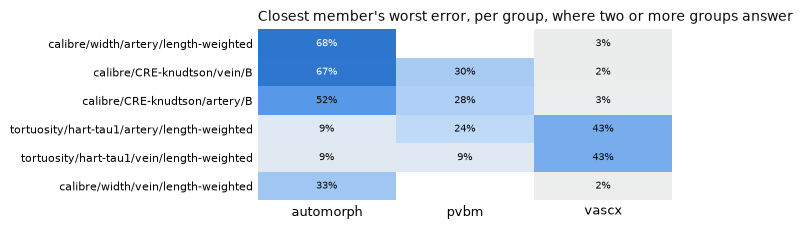

In [20]:
if len(shared):
    import matplotlib.pyplot as plt

    se.heat(shared, "Closest member's worst error, per group, where two or more groups answer")
    plt.show()

### 6.3 Sensitivity to rotation, by group

The same comparison for rotation: per canonical name and group, the steadiest member's worst spread
across the seven angles. The vertical and horizontal cup-to-disc ratios are left out, as everywhere.

In [21]:
steady = se.rotation(EVIDENCE, named=True).rename("spread").reset_index()
steady["group"] = steady["implementation"].map(GROUP_OF)
GROUP_ROTATION = (
    steady.groupby(["canonical", "group"])["spread"].min().unstack("group").reindex(columns=list(GROUPS))
)
moving = GROUP_ROTATION[(GROUP_ROTATION > ROTATION_TOLERANCE).any(axis=1)]
print(
    f"{len(moving)} of {len(GROUP_ROTATION)} names move by more than {ROTATION_TOLERANCE:.0%} in at "
    f"least one group's steadiest member; worst spread:"
)
se.legible(moving.loc[moving.max(axis=1).sort_values(ascending=False).index])

37 of 55 names move by more than 10% in at least one group's steadiest member; worst spread:


group,automorph,pvbm,vascx
canonical,,,
tortuosity/grisan-density/vein/B/mean,700.0%,—,—
tortuosity/grisan-density/artery/B/mean,350.7%,—,—
tortuosity/grisan-density/artery/C/mean,350.2%,—,—
tortuosity/grisan-density/vein/C/mean,350.2%,—,—
tortuosity/grisan-density/vessels/B/mean,313.1%,—,—
tortuosity/grisan-density/artery/mean,280.0%,—,—
tortuosity/grisan-density/vein/length-weighted,265.4%,—,—
tortuosity/grisan-density/vessels/length-weighted,265.1%,—,—
tortuosity/grisan-density/artery/length-weighted,264.8%,—,—


### 6.4 By family of biomarker

Per family and group: how many names the group answers, how many of those its closest member gets
within 25% of the geometry on every shape and angle, and how many hold within 10% under rotation.

In [22]:
rows = []
for group in GROUPS:
    truth = GROUP_TRUTH[group].dropna()
    turning = GROUP_ROTATION[group].dropna() if group in GROUP_ROTATION else pd.Series(dtype=float)
    for family in sorted({FAMILY(name) for name in truth.index}):
        mine = truth[[FAMILY(name) == family for name in truth.index]]
        spin = turning[[FAMILY(name) == family for name in turning.index]]
        rows.append(
            {
                "family": family,
                "group": group,
                "names answered": len(mine),
                "within 25% everywhere": f"{int((mine <= GROUND_TRUTH_TOLERANCE).sum())} / {len(mine)}",
                "steady within 10%": f"{int((spin <= ROTATION_TOLERANCE).sum())} / {len(spin)}",
                "median of worst errors": se.readable(mine.median()),
            }
        )
pd.DataFrame(rows).set_index(["family", "group"])

,,names answered,within 25% everywhere,steady within 10%,median of worst errors
family,group,,,,
calibre,automorph,7,0 / 7,3 / 7,67.4%
density,automorph,6,5 / 6,5 / 6,11.2%
landmarks,automorph,2,2 / 2,0 / 0,0.0%
tortuosity,automorph,24,12 / 24,9 / 24,"1,648×"
calibre,pvbm,6,1 / 6,0 / 6,30.6%
density,pvbm,10,3 / 10,5 / 10,27.5%
topology,pvbm,2,0 / 2,0 / 2,50×
tortuosity,pvbm,4,3 / 4,1 / 4,19.4%
calibre,vascx,4,4 / 4,4 / 4,2.5%


### 6.5 Each group's best and worst biomarkers, side by side

Per group, how many canonical names its closest member measures to within the noise floor
everywhere, then the names it measures best and, of those out by more than 25%, the five where even its
closest member is furthest from the geometry. The group notebooks give the
same per member, with the shape each worst case happened on.

In [23]:
for group in GROUPS:
    column = GROUP_TRUTH[group].dropna().sort_values()
    exact = column[column == 0]
    # The same rule as each group notebook's: the closest half at most, and as worst only what is
    # out of tolerance somewhere, so a 2% error is never shown as a worst case.
    best = column.head(max(len(exact), min(5, (len(column) + 1) // 2)))
    rest = column.drop(index=best.index)
    worst = rest[rest > GROUND_TRUTH_TOLERANCE].tail(5).iloc[::-1]
    display(
        Markdown(
            f"**{group}** — {len(exact)} of {len(column)} names within the floor everywhere. "
            f"Best, then worst (out by more than {GROUND_TRUTH_TOLERANCE:.0%}), by the closest member's worst error:"
        )
    )
    display(
        pd.concat({"best": best, "worst": worst})
        .map(se.readable)
        .rename("closest member's worst error")
        .to_frame()
    )

**automorph** — 2 of 39 names within the floor everywhere. Best, then worst (out by more than 25%), by the closest member's worst error:

closest member's worst error
      canonical                                                            
best  landmarks/CDR-horizontal                                         0.0%
      landmarks/CDR-vertical                                           0.0%
      density/over-image/vein                                          1.7%
      density/over-image/vessels                                       1.7%
      density/over-image/artery                                        5.0%
worst tortuosity/grisan-density/artery/B/mean                      335,084×
      tortuosity/grisan-density/vein/B/mean                        334,735×
      tortuosity/grisan-density/vessels/B/mean                     331,336×
      tortuosity/grisan-density/artery/C/mean                      203,093×
      tortuosity/grisan-density/vein/C/mean                        203,091×

**pvbm** — 0 of 22 names within the floor everywhere. Best, then worst (out by more than 25%), by the closest member's worst error:

closest member's worst error
      canonical                                                             
best  density/area/vein                                                 1.7%
      density/skeleton-length-rooted/vein                               4.5%
      density/area/artery                                               5.0%
      tortuosity/hart-tau1/vein/length-weighted                         9.5%
      tortuosity/hart-tau1/artery/median                               15.0%
worst topology/junctions/vein                                            57×
      topology/junctions/artery                                          43×
      calibre/CRE-hubbard/vein/B                                       55.8%
      calibre/AVR-hubbard/both/B                                       47.0%
      density/multifractal-d0/vein                                     33.3%

**vascx** — 0 of 6 names within the floor everywhere. Best, then worst (out by more than 25%), by the closest member's worst error:

closest member's worst error
      canonical                                                               
best  calibre/width/vein/length-weighted                                  2.2%
      calibre/CRE-knudtson/vein/B                                         2.4%
      calibre/width/artery/length-weighted                                2.7%
worst tortuosity/hart-tau1/artery/length-weighted                        43.5%
      tortuosity/hart-tau1/vein/length-weighted                          43.4%

### 6.6 What the comparison shows, and which lineage to reach for

*Our reading of §6.1–6.5, on the run of 2026-11-22. Each lineage is represented by its closest
member, so a cell says what the best of that code can do.*

**The three lineages barely overlap.** Of 57 canonical names with a ground truth, 51 are answered
by one lineage alone, 2 by two and 4 by all three: the zone-B Knudtson equivalents and
length-weighted Hart τ1 (arc over chord), for arteries and for veins. A reader choosing software is
mostly choosing which questions can be asked at all (§6.1). Only the AutoMorph lineage answers the
cup-to-disc ratios, and only PVBM's answers a topology question.

**Where they do overlap, they disagree by an order of magnitude** (§6.2). On calibre, VascX is
within 2.2–2.9%, PVBM's Knudtson equivalents 28.5–30.4% and the AutoMorph lineage's 32.7–67.7%. On
tortuosity the order reverses: the AutoMorph lineage (AutoMorphClass) is within 8.6–9.5%, PVBM's
(OCULAR) 9.5–23.9%, and VascX 43%, all of it on the Koch curve.

**Each lineage has one failure the others do not share** (§6.3): Grisan density in the AutoMorph
lineage, which moves by 180–700% under rotation even in its steadiest member; junction counts in
PVBM's, which move by 200–210% and report junctions on an unbranched curve; and tortuosity on a
kinked curve in VascX.

Which to reach for, **per question**, with the runner-up and what would change the answer:

| Question | Reach for | Its worst error | Runner-up | Caveat | Seconds an image |
| --- | --- | --- | --- | --- | --- |
| Vessel width, central retinal equivalents | VascX | 2.2–2.9% | PVBM lineage, 28.5–30.4% (Knudtson) | judged on three shapes only | 5.2 |
| Arc-over-chord tortuosity | AutoMorph lineage (AutoMorphClass) | 8.6–9.5% | PVBM lineage (OCULAR), level on veins at 9.5%, 23.9% on arteries | close on veins; not a margin there | 1.5 (OCULAR 4.8) |
| Cup-to-disc ratio | AutoMorph lineage (either rewrite) | inside the noise floor | none: no other lineage computes it | a drawn ellipse is the easiest cup there is | 1.5 / 7.0 |
| Vessel area or density | either the AutoMorph rewrites or the PVBM lineage | 1.7–5.3%, each on its own name | — | different canonical names, not directly compared | 1.5 / 4.8 |
| Branching, junctions | none | 43–57× on `koch` (PVBM lineage) | — | only one lineage answers, and it fails | — |
| Grisan density | none | 3,297–3,325× even in its closest member (AutoMorphClass) | — | only one lineage answers, and it fails | — |

The timings are from this machine on one run and reproduce only as ratios (the results page, §8).
None of this says anything about photographs: these shapes are clean, complete and drawn to a known
scale.